# Notebook 02: Data Cleaning and Preprocessing

**Purpose.** Turn the raw table into feature matrices suitable for distance-based clustering. K-Means and hierarchical clustering both compare users by distance, so every step here is really a decision about **what "similar users" means**.

For each significant decision, this notebook states what was done, why, what the alternatives were, and what effect the choice may have.

In [1]:
import sys
sys.path.append("..")

import json

import numpy as np
import pandas as pd
from IPython.display import display

from src.data_loader import ensure_output_dirs, load_config, load_raw_data, project_path
from src.preprocessing import (
    add_skips_per_listening_hour,
    add_tenure_months,
    build_mixed_representation,
    build_numeric_representation,
    cronbach_alpha,
    iqr_outlier_summary,
    skewness_with_log1p,
    validate_feature_matrix,
)
from src.visualization import apply_plot_style, plot_numeric_histograms, save_figure

config = load_config()
ensure_output_dirs(config)
apply_plot_style()
PROCESSED_DIR = project_path(config["paths"]["processed_dir"])

NUMERIC_FEATURES = config["columns"]["representation_a_numeric"]
CATEGORICAL_FEATURES = config["columns"]["representation_b_categorical"]
OUTCOME_COLUMNS = config["columns"]["outcome_related"]

df = load_raw_data(config)
df.shape

(50000, 18)

## A. Cleaning

| Issue | Finding (Notebook 01) | Decision | Reason |
|---|---|---|---|
| Missing values | None | No imputation | Nothing to fill |
| Duplicate records | None, with or without `user_id` | No rows removed | Every user is distinct |
| Invalid ranges and inconsistent categories | None | No changes | Ages, ratings and category spellings are all valid |
| Cross-column oddities | Found (for example Free users marked as converted) | Keep and report | The meanings are unconfirmed, and deleting rows based on guesses would be arbitrary |
| Zero listening hours with skips | 327 users (0.65%) | Keep; test the effect in Notebook 05 | This one affects clustering inputs, so it gets a sensitivity check rather than silent deletion |

The checks below confirm the facts this table relies on, so that the notebook still fails loudly if the input file ever changes.

In [2]:
assert df.isna().sum().sum() == 0
assert not df.duplicated().any()
assert df["user_id"].is_unique
assert df["age"].between(16, 60).all()
assert df["music_suggestion_rating_1_to_5"].between(1, 5).all()
assert (df[["avg_listening_hours_per_week", "playlists_created", "avg_skips_per_day"]] >= 0).all().all()

zero_hours_users = int((df["avg_listening_hours_per_week"] == 0).sum())
print(f"All checks passed. Rows kept: {len(df):,} of {len(df):,}. Zero-hour users kept: {zero_hours_users}.")

All checks passed. Rows kept: 50,000 of 50,000. Zero-hour users kept: 327.


### Outliers

**What:** count values outside the 1.5 x IQR fences for the candidate features.

**Why not delete them:** clustering has no "correct" target to protect, and an unusually heavy listener is a real kind of user, not a mistake. Deleting them would remove the very users a segmentation is supposed to describe. **Alternative:** winsorizing (capping) or removal; **effect** would be slightly tighter clusters at the cost of misdescribing the extremes.

In [3]:
iqr_outlier_summary(df, NUMERIC_FEATURES).round(2)

,feature,lower_fence,upper_fence,min,max,outliers,percent
0,avg_listening_hours_per_week,-0.82,20.78,0.0,26.25,166,0.33
1,playlists_created,0.00,16.00,0.0,23.00,185,0.37
2,avg_skips_per_day,2.00,18.00,1.0,25.00,413,0.83
3,music_suggestion_rating_1_to_5,0.00,8.00,1.0,5.00,0,0.00


**Result and decision.** Each behavioural feature has under 1% of its values outside the fences (0.33%, 0.37%, 0.83% and 0%), and the extremes are believable. All are kept. Because these features are nearly symmetric with light tails, a few extreme values have little power to distort the centroids.

## B. Feature engineering

We create a feature only if it means something and adds information. Three candidates are examined.

### 1. Account tenure (from `signup_date`)
A raw date cannot enter a distance calculation, but elapsed time can. The file documents no snapshot date, so tenure is measured up to the latest signup in the data. Treat it as a relative measure.

In [4]:
df = add_tenure_months(df)
print(f"Snapshot assumed: {df['signup_date'].max().date()}")
print(df["tenure_months"].describe().round(1).to_string())
print("Correlation with the behavioural features:")
print(df[NUMERIC_FEATURES].corrwith(df["tenure_months"]).round(3).to_string())

Snapshot assumed: 2026-03-01
count    50000.0
mean        48.9
std         28.3
min          0.0
25%         24.4
50%         48.9
75%         73.4
max         97.9
Correlation with the behavioural features:
avg_listening_hours_per_week      0.008
playlists_created                 0.005
avg_skips_per_day                 0.005
music_suggestion_rating_1_to_5   -0.003


**Decision: tenure is used for interpretation only.** It correlates with no behavioural feature (|r| of 0.008 or less), and it describes how long ago someone joined rather than how they listen. It also depends on an assumed snapshot date. **Alternative:** add it as a fifth input. **Effect:** the distances would gain one more independent dimension, and clusters would partly divide users by signup date.

### 2. Skips per listening hour

This looks like a natural measure of skipping intensity, so it deserves a proper look. `avg_skips_per_day` is converted against daily listening time (`hours per week / 7`). The ratio is undefined for users with zero hours.

In [5]:
df = add_skips_per_listening_hour(df)
ratio = df["skips_per_listening_hour"]
print(f"Undefined for {ratio.isna().sum()} users; median {ratio.median():.2f}; 99th percentile {ratio.quantile(0.99):.2f}; maximum {ratio.max():.2f}; skewness {ratio.skew():.1f}")
print(f"Correlation with listening hours: {ratio.corr(df['avg_listening_hours_per_week']):.3f}")
print(f"Correlation with skips per day: {ratio.corr(df['avg_skips_per_day']):.3f}")

Undefined for 327 users; median 6.95; 99th percentile 51.90; maximum 8400.00; skewness 84.6
Correlation with listening hours: -0.126
Correlation with skips per day: 0.040


**Decision: descriptive use only.** The ratio is undefined for 327 users and has an extremely long tail (median 6.95, 99th percentile 51.9, maximum 8,400, skew 84.6), caused by users with very few listening hours rather than by unusual skipping. In a distance calculation, a few such users would dominate. It also adds no new information, since it is computed from two features that are already included. **Alternative:** a logged ratio would tame the tail, but it would still double-count hours and skips.

### 3. A composite engagement score?

The project brief anticipated `engaging_score` and `engaging_level` columns. **Neither exists in this file**, so there is nothing to compare or de-duplicate. Could we build one ourselves? A composite score only makes sense if its ingredients move together, which is what **Cronbach's alpha** measures: values near 0 mean the items share nothing, and values around 0.7 or more are conventionally considered acceptable for a scale.

In [6]:
alpha = cronbach_alpha(df[NUMERIC_FEATURES])
print(f"Cronbach's alpha of the four behavioural features: {alpha:.3f}")

Cronbach's alpha of the four behavioural features: 0.005


**Decision: no composite engagement score.** An alpha of 0.005 means the four features share essentially nothing. Adding them up would produce a number with no coherent meaning, so inventing one would be artificial. Each feature stays separate.

## C. Feature selection

**Primary feature set (Representation A):** `avg_listening_hours_per_week`, `playlists_created`, `avg_skips_per_day`, `music_suggestion_rating_1_to_5`.

| Excluded column | Reason | Used later? |
|---|---|---|
| `user_id` | Identifier, carries no behaviour | Key for joining labels |
| `signup_date` | Raw date; tenure derived instead | Tenure described after clustering |
| `months_inactive` | Outcome-like: it drives `subscription_status` | Described after clustering |
| `inactive_3_months_flag` | Exact function of `months_inactive` | Described after clustering |
| `subscription_status` | Outcome | Described after clustering |
| `ad_conversion_to_subscription` | Outcome | Described after clustering |
| `ad_interaction` | Precondition of the conversion outcome | Described after clustering |
| `subscription_type` | Commercial status, not behaviour | Described after clustering |
| `age`, `country` | Demographics, not behaviour | Described after clustering |
| `most_liked_feature`, `desired_future_feature` | Survey opinions, not behaviour | Described after clustering |

**Why keep inactivity out?** If it were an input, clusters would partly reflect inactivity by construction, and then "this cluster has high inactivity" would be circular rather than a finding. Keeping it out means any later association between clusters and inactivity is real evidence.

**Assumption to note:** the rating is ordinal, and using it in Euclidean distance treats the gap between 1 and 2 as equal to the gap between 4 and 5. This is a common simplification, and its influence is tested in Notebook 05 by removing the rating entirely.

**Alternative:** include inactivity as an input to build "lifecycle" segments. That is a valid but different project, and it would break the no-leakage rule set for this one.

## D. Numerical preprocessing

### Should we apply `log1p`?

`log1p(x) = log(1 + x)` compresses long right tails and is useful for nonnegative counts with heavy skew. It should be used only when there is a tail to compress.

**Count versus binary variables.** A count such as playlists has many ordered values, so compressing large values changes the shape of the distribution in a meaningful way. A binary 0/1 variable has only two values: `log1p` merely maps 1 to 0.693, which changes no shape and only shrinks that variable's scale. Applying it to binary variables therefore has no statistical benefit and quietly changes its weight.

In [7]:
skew_table = skewness_with_log1p(df, NUMERIC_FEATURES + ["months_inactive"])
skew_table

,skew_raw,skew_after_log1p
avg_listening_hours_per_week,0.032,-1.721
playlists_created,0.355,-0.712
avg_skips_per_day,0.314,-0.646
music_suggestion_rating_1_to_5,-0.598,-1.242
months_inactive,1.984,0.478


**Decision: no `log1p`.** For all four selected features, the transform makes the shape *worse*: hours go from skew 0.03 to -1.72, playlists from 0.36 to -0.71, skips from 0.31 to -0.65, and rating from -0.60 to -1.24. Applying a log to a roughly symmetric variable creates a left tail. Only `months_inactive` would improve (1.98 to 0.48), and it is not a clustering input.

### Which scaler?

Without scaling, Euclidean distance would be dominated by whichever feature has the largest numeric range. Two standard options:

- **StandardScaler:** `(x - mean) / standard deviation`. Every feature ends up with variance 1, so each contributes equally on average. It is sensitive to extreme outliers.
- **RobustScaler:** `(x - median) / IQR`. Resistant to outliers, but it does *not* equalize variance.

The next cell shows how much each feature would weigh under each option.

In [8]:
standard_matrix, standard_scaler = build_numeric_representation(df, NUMERIC_FEATURES, "standard")
robust_matrix, _ = build_numeric_representation(df, NUMERIC_FEATURES, "robust")
scaler_comparison = pd.DataFrame(
    {
        "raw_std": df[NUMERIC_FEATURES].std(),
        "raw_iqr": df[NUMERIC_FEATURES].quantile(0.75) - df[NUMERIC_FEATURES].quantile(0.25),
        "variance_after_standard": standard_matrix.var(),
        "variance_after_robust": robust_matrix.var(),
    }
).round(3)
scaler_comparison

,raw_std,raw_iqr,variance_after_standard,variance_after_robust
avg_listening_hours_per_week,3.969,5.4,1.0,0.540
playlists_created,2.832,4.0,1.0,0.501
avg_skips_per_day,3.166,4.0,1.0,0.626
music_suggestion_rating_1_to_5,1.114,2.0,1.0,0.310


**Decision: StandardScaler.** It gives every feature a variance of exactly 1, so each contributes equally to distances. RobustScaler would leave unequal variances, from 0.31 for rating to 0.63 for skips, so rating would count for only about half as much as skips. That weighting has no behavioural justification, and RobustScaler's main advantage (resistance to extreme outliers) is not needed here. **Effect:** Notebook 05 re-fits both models with RobustScaler to measure how much this choice matters.

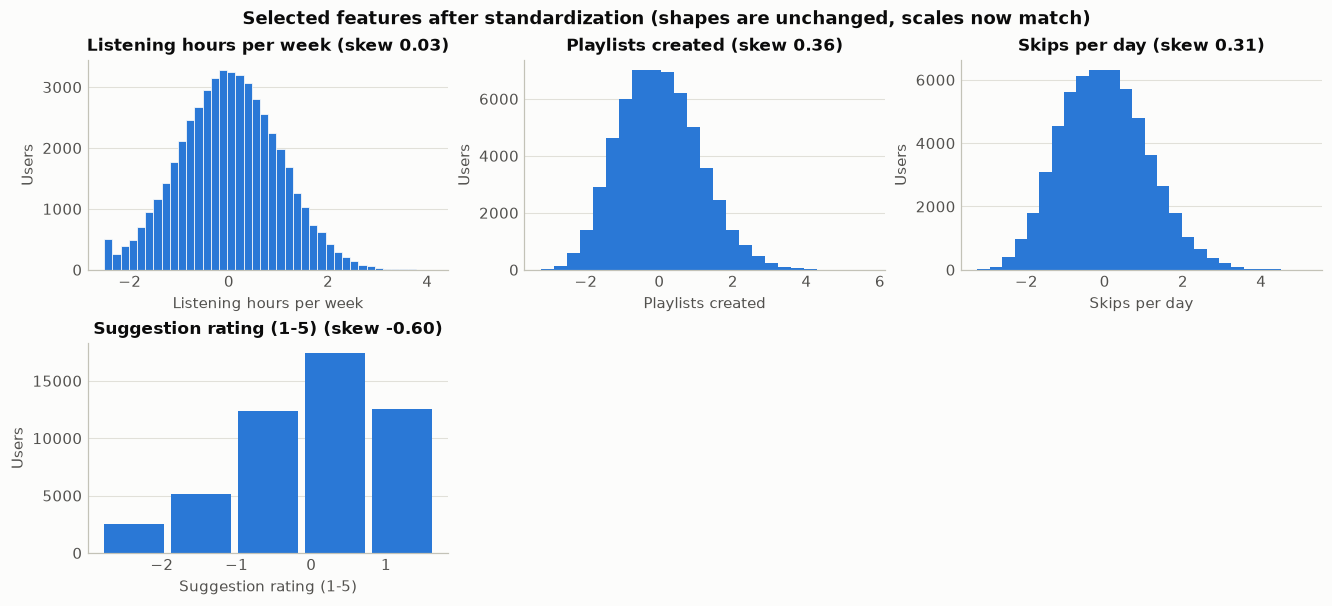

In [9]:
fig = plot_numeric_histograms(
    standard_matrix.reset_index(drop=True),
    NUMERIC_FEATURES,
    "Selected features after standardization (shapes are unchanged, scales now match)",
)
save_figure(fig, "preprocessing_scaled_features", config)

## E. Categorical preprocessing

| Option | Assessment |
|---|---|
| Integer codes (Pop = 1, Rock = 2, ...) | **Rejected.** This invents an order and distances that do not exist. |
| Frequency encoding | **Rejected.** Categories here have nearly equal frequency, so almost all would collapse to the same number. |
| Grouping rare categories | **Not needed.** Notebook 01 found no rare categories. |
| One-hot encoding | **Used for Representation B.** Each category becomes a 0/1 column, so every pair of different categories is equally far apart. |

**Which categorical variables?** `favorite_genre` (12 levels) and `primary_device` (5 levels) describe listening habits. `country` is demographic, and `most_liked_feature` and `desired_future_feature` are opinions, so they stay out. This keeps the matrix at 21 columns rather than 47.

**How one-hot encoding changes geometry.** Adding 17 columns gives the space many extra directions. Two users with different genres are always sqrt(2), about 1.41, apart on those columns, regardless of how similar their listening is. Standardizing the dummy columns too would make it worse: each rare dummy would gain variance 1, so a 12-level genre would weigh about as much as 12 numeric features.

We therefore keep dummies at 0/1. A categorical variable with K balanced levels then has total variance `1 - 1/K`, close to the variance of 1 for one standardized numeric feature, so each *original variable* carries similar weight. The next cell verifies this.

In [10]:
mixed_matrix = build_mixed_representation(df, NUMERIC_FEATURES, CATEGORICAL_FEATURES)

variance_by_variable = {feature: mixed_matrix[feature].var() for feature in NUMERIC_FEATURES}
for variable in CATEGORICAL_FEATURES:
    dummies = [column for column in mixed_matrix.columns if column.startswith(f"{variable}_")]
    variance_by_variable[f"{variable} ({len(dummies)} dummies)"] = mixed_matrix[dummies].var().sum()
pd.Series(variance_by_variable, name="total_variance").round(3).to_frame()

,total_variance
avg_listening_hours_per_week,1.000
playlists_created,1.000
avg_skips_per_day,1.000
music_suggestion_rating_1_to_5,1.000
favorite_genre (12 dummies),0.917
primary_device (5 dummies),0.800


**Representation A** (four standardized numeric features) is the primary basis for the K-Means versus CAH comparison, because it is easy to interpret and avoids arbitrary categorical distances. **Representation B** is a comparison only. It is not assumed to be better just because it contains more columns.

## F. Validate and save

We verify the shape, missingness, finiteness and scaling of each matrix, and confirm that no identifier or outcome column has slipped in.

In [11]:
forbidden_columns = OUTCOME_COLUMNS + ["user_id", "signup_date", "subscription_type", "ad_interaction", "age", "country"]

summary_a = validate_feature_matrix(standard_matrix, len(df), 4, forbidden_columns)
summary_b = validate_feature_matrix(mixed_matrix, len(df), 21, forbidden_columns)

assert np.allclose(standard_matrix.mean(), 0, atol=1e-9), "Standardized means should be 0"
assert np.allclose(standard_matrix.std(ddof=0), 1, atol=1e-9), "Standardized variances should be 1"
dummy_columns = mixed_matrix.columns.difference(NUMERIC_FEATURES)
assert set(np.unique(mixed_matrix[dummy_columns].to_numpy())) == {0.0, 1.0}, "Dummies should be 0/1"
assert (mixed_matrix[[c for c in dummy_columns if c.startswith("favorite_genre_")]].sum(axis=1) == 1).all()
assert (mixed_matrix[[c for c in dummy_columns if c.startswith("primary_device_")]].sum(axis=1) == 1).all()

display(pd.DataFrame({"Representation A": summary_a, "Representation B": summary_b}))

,Representation A,Representation B
rows,50000,50000
columns,4,21
missing_values,0,0
all_finite,True,True
forbidden_columns_found,0,0


In [12]:
df.to_csv(PROCESSED_DIR / "users_clean.csv", index=False)
standard_matrix.to_csv(PROCESSED_DIR / "features_representation_a.csv")
mixed_matrix.to_csv(PROCESSED_DIR / "features_representation_b.csv")

preprocessing_record = {
    "rows_in": len(load_raw_data(config)),
    "rows_out": len(df),
    "representation_a_features": NUMERIC_FEATURES,
    "representation_b_features": list(mixed_matrix.columns),
    "scaler": "StandardScaler (numeric features only)",
    "scaler_mean": dict(zip(NUMERIC_FEATURES, standard_scaler.mean_.round(6).tolist())),
    "scaler_std": dict(zip(NUMERIC_FEATURES, standard_scaler.scale_.round(6).tolist())),
    "log1p_columns": config["preprocessing"]["log1p_columns"],
    "one_hot_columns": CATEGORICAL_FEATURES,
    "dummy_columns_scaled": False,
    "tenure_snapshot": str(df["signup_date"].max().date()),
    "excluded_from_clustering": forbidden_columns,
}
with open(PROCESSED_DIR / "preprocessing_config.json", "w", encoding="utf-8") as file:
    json.dump(preprocessing_record, file, indent=2)

# Read the saved files back to confirm they match what is in memory.
reloaded_a = pd.read_csv(PROCESSED_DIR / "features_representation_a.csv", index_col="user_id")
reloaded_b = pd.read_csv(PROCESSED_DIR / "features_representation_b.csv", index_col="user_id")
assert np.allclose(reloaded_a.to_numpy(), standard_matrix.to_numpy())
assert np.allclose(reloaded_b.to_numpy(), mixed_matrix.to_numpy())
print("Saved and verified:", sorted(path.name for path in PROCESSED_DIR.glob("*") if path.is_file() and path.name != ".gitkeep"))

Saved and verified: ['features_representation_a.csv', 'features_representation_b.csv', 'preprocessing_config.json', 'users_clean.csv']


## Conclusion

- **All 50,000 rows are kept.** No values were imputed.
- **Representation A:** four standardized behavioural features; this is the primary basis for comparing the algorithms.
- **Representation B:** Representation A plus 17 one-hot columns for genre and device (21 columns in total); used only as a comparison.
- **Engineered features:** tenure and skips per listening hour are stored for interpretation only.
- **Verification:** both matrices are complete, finite and correctly scaled, contain no identifier or outcome column, and match their saved files.